# Preprocessing Data
## Bima Satriawan - 5054251031

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('train.csv')

In [4]:
df.shape

(1460, 81)

In [5]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

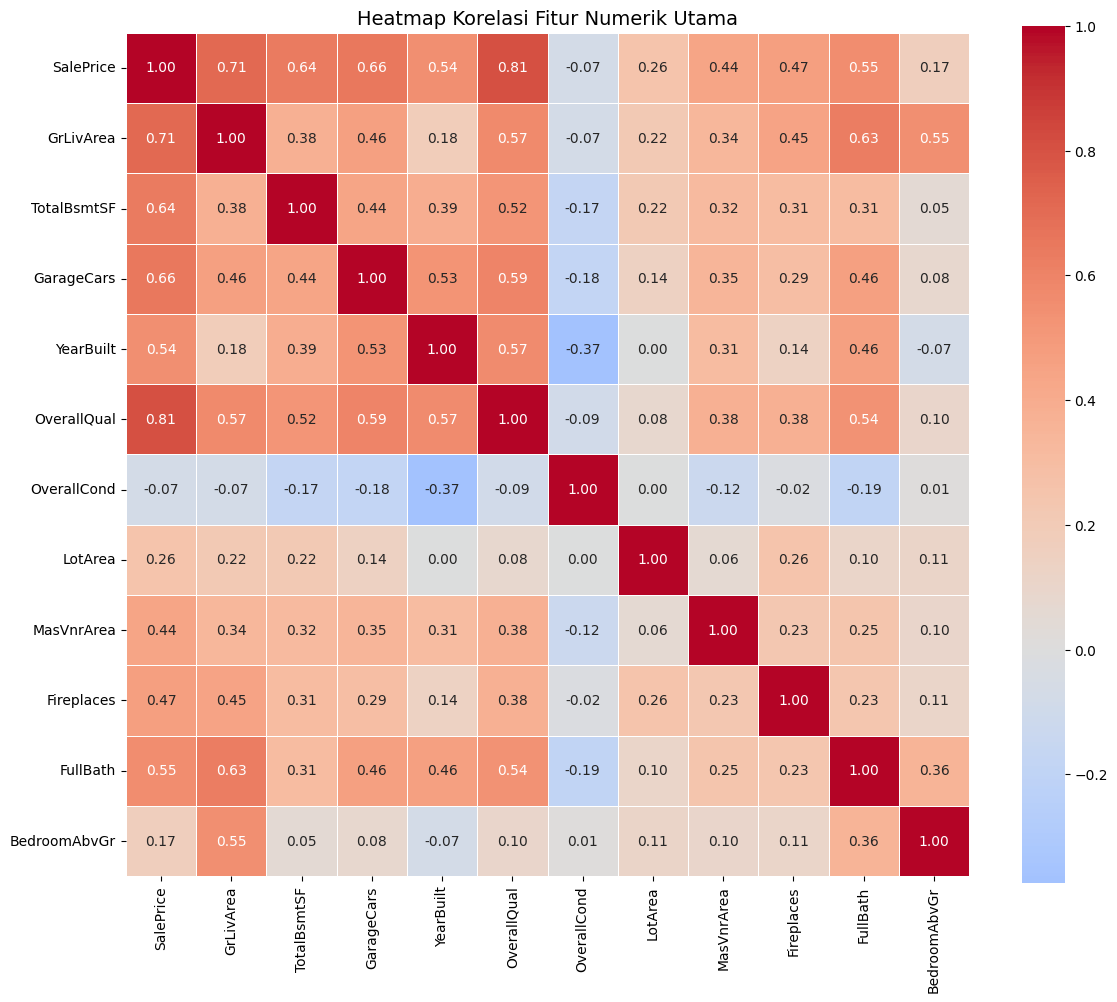

In [47]:
num_cols_key = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'GarageCars',
                'YearBuilt', 'OverallQual', 'OverallCond', 'LotArea',
                'MasVnrArea', 'Fireplaces', 'FullBath', 'BedroomAbvGr']

plt.figure(figsize=(12, 10))
corr = df[num_cols_key].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Numerik Utama', fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
missing = (df.isnull().sum() / len(df) * 100).round(2)
missing = missing[missing > 0]
missing = missing.sort_values(ascending=False)
print(missing)

PoolQC          99.52
MiscFeature     96.30
Alley           93.77
Fence           80.75
MasVnrType      59.73
FireplaceQu     47.26
LotFrontage     17.74
GarageType       5.55
GarageYrBlt      5.55
GarageFinish     5.55
GarageQual       5.55
GarageCond       5.55
BsmtExposure     2.60
BsmtFinType2     2.60
BsmtQual         2.53
BsmtCond         2.53
BsmtFinType1     2.53
MasVnrArea       0.55
Electrical       0.07
dtype: float64


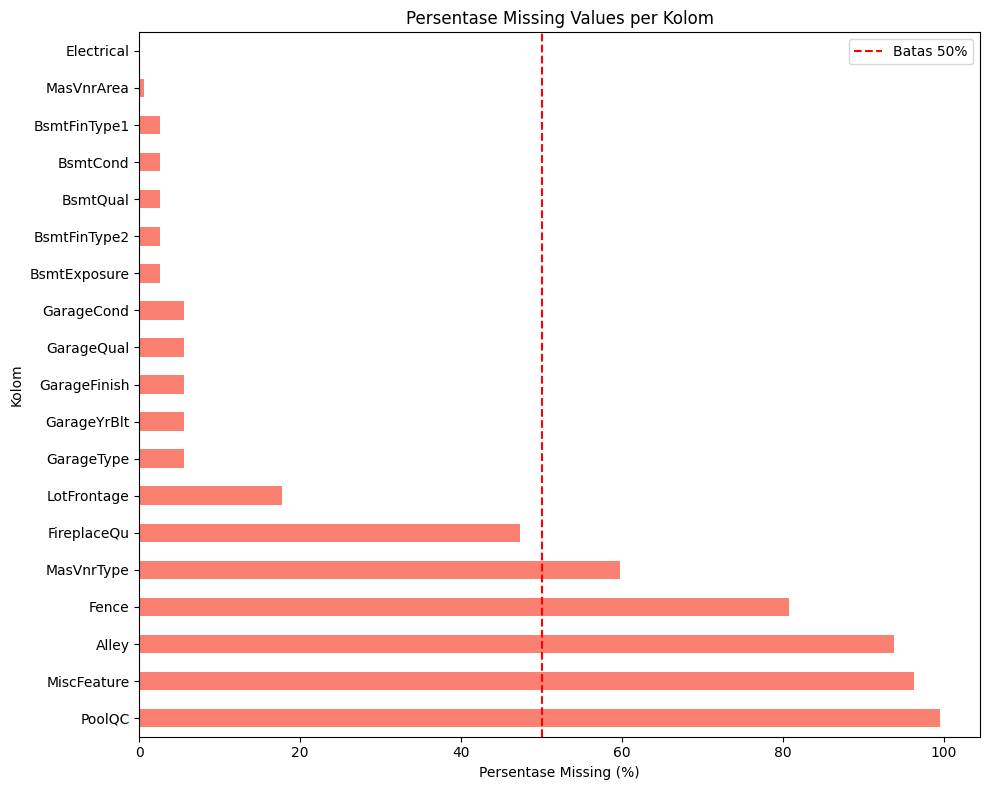

In [ ]:
plt.figure(figsize=(10, 8))
missing.plot(kind='barh', color='salmon')
plt.axvline(x=50, color='red', linestyle='--', label='Batas 50%')
plt.xlabel('Persentase Missing (%)')
plt.ylabel('Kolom')
plt.title('Persentase Missing Values per Kolom')
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
cols_to_drop = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']

df = df.drop(columns=cols_to_drop, errors='ignore')
print(df.shape)

(1460, 76)


In [27]:
missing_after = (df.isnull().sum() / len(df) * 100).round(2)
missing_after = missing_after[missing_after > 0].sort_values(ascending=False)
print(missing_after)

FireplaceQu     47.26
LotFrontage     17.74
GarageYrBlt      5.55
GarageFinish     5.55
GarageType       5.55
GarageQual       5.55
GarageCond       5.55
BsmtExposure     2.60
BsmtFinType2     2.60
BsmtCond         2.53
BsmtQual         2.53
BsmtFinType1     2.53
MasVnrArea       0.55
Electrical       0.07
dtype: float64


In [28]:
cat_none_cols = [
    'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2'
]
for col in cat_none_cols:
    df[col] = df[col].fillna('None')

df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)

df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())
df['MasVnrArea'] = df['MasVnrArea'].fillna(df['MasVnrArea'].median())
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

print(f"Total missing values: {df.isnull().sum().sum()}")
print(f"Shape akhir: {df.shape}")

Total missing values: 0
Shape akhir: (1460, 76)


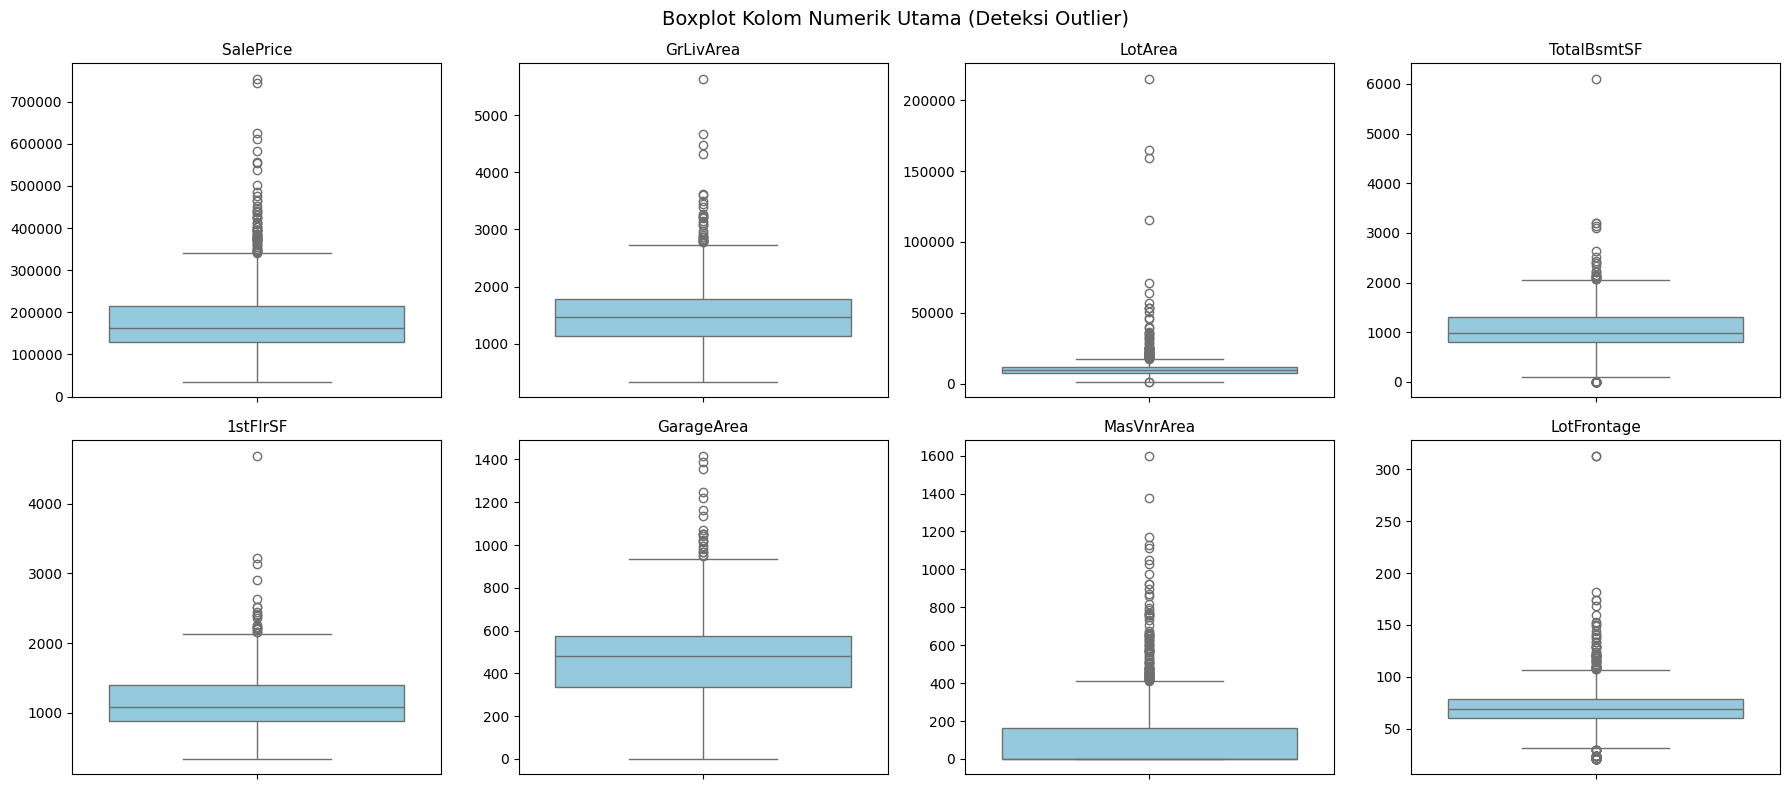

In [29]:
key_num_cols = [
    'SalePrice', 'GrLivArea', 'LotArea', 'TotalBsmtSF',
    '1stFlrSF', 'GarageArea', 'MasVnrArea', 'LotFrontage'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(key_num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col, fontsize=11)
    axes[i].set_ylabel('')

plt.suptitle('Boxplot Kolom Numerik Utama (Deteksi Outlier)', fontsize=14)
plt.tight_layout()
plt.show()

In [34]:
key_num_cols = [
    'SalePrice', 'GrLivArea', 'LotArea', 'TotalBsmtSF',
    '1stFlrSF', 'GarageArea', 'MasVnrArea', 'LotFrontage'
]

for col in key_num_cols:
    Q1 = df[col].quantile(0.25)
    
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outlier = df[(df[col] < lower) | (df[col] > upper)].shape[0]

    print(f"{col:<20} {n_outlier:<8}")

SalePrice            61      
GrLivArea            31      
LotArea              69      
TotalBsmtSF          61      
1stFlrSF             20      
GarageArea           21      
MasVnrArea           98      
LotFrontage          106     


In [35]:
print(f"Shape sebelum handle outlier: {df.shape}")

print("DATA DENGAN GrLivArea > 4000")
print(df[df['GrLivArea'] > 4000][['GrLivArea', 'SalePrice', 'OverallQual']])

print("DATA DENGAN SalePrice > 500000")
print(df[df['SalePrice'] > 500000][['GrLivArea', 'SalePrice', 'OverallQual']])

df = df[df['GrLivArea'] < 4000]
df = df[df['SalePrice'] < 500000]

df = df.reset_index(drop=True)

print("HASIL AKHIR")
print(f"Shape sebelum: (1460, 76)")
print(f"Shape sesudah: {df.shape}")
print(f"Jumlah baris dihapus: {1460 - df.shape[0]}")
print(f"Persentase data hilang: {((1460 - df.shape[0]) / 1460 * 100):.2f}%")

Shape sebelum handle outlier: (1460, 76)
DATA DENGAN GrLivArea > 4000
      GrLivArea  SalePrice  OverallQual
523        4676     184750           10
691        4316     755000           10
1182       4476     745000           10
1298       5642     160000           10
DATA DENGAN SalePrice > 500000
      GrLivArea  SalePrice  OverallQual
178        2234     501837            9
440        2402     555000           10
691        4316     755000           10
769        3279     538000            8
803        2822     582933            9
898        2364     611657            9
1046       2868     556581            9
1169       3627     625000           10
1182       4476     745000           10
HASIL AKHIR
Shape sebelum: (1460, 76)
Shape sesudah: (1449, 76)
Jumlah baris dihapus: 11
Persentase data hilang: 0.75%


In [36]:
X = df.drop(columns=['Id', 'SalePrice'])
y = df['SalePrice']

In [37]:
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Daftar kolom kategorik:")
for col in cat_cols:
    print(f"  - {col} ({X[col].nunique()} unique values)")

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

print(f"Kolom baru hasil encoding: {X_encoded.shape[1] - len(num_cols)}")

Daftar kolom kategorik:
  - MSZoning (5 unique values)
  - Street (2 unique values)
  - LotShape (4 unique values)
  - LandContour (4 unique values)
  - Utilities (2 unique values)
  - LotConfig (5 unique values)
  - LandSlope (3 unique values)
  - Neighborhood (25 unique values)
  - Condition1 (9 unique values)
  - Condition2 (8 unique values)
  - BldgType (5 unique values)
  - HouseStyle (8 unique values)
  - RoofStyle (6 unique values)
  - RoofMatl (7 unique values)
  - Exterior1st (15 unique values)
  - Exterior2nd (16 unique values)
  - ExterQual (4 unique values)
  - ExterCond (5 unique values)
  - Foundation (6 unique values)
  - BsmtQual (5 unique values)
  - BsmtCond (5 unique values)
  - BsmtExposure (5 unique values)
  - BsmtFinType1 (7 unique values)
  - BsmtFinType2 (7 unique values)
  - Heating (6 unique values)
  - HeatingQC (5 unique values)
  - CentralAir (2 unique values)
  - Electrical (5 unique values)
  - KitchenQual (4 unique values)
  - Functional (7 unique value

In [38]:
from sklearn.preprocessing import StandardScaler

# Standarisasi semua kolom numerik
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_encoded),
    columns=X_encoded.columns,
    index=X_encoded.index
)

X = df.drop(columns=['Id', 'SalePrice'])
y = df['SalePrice']

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (1449, 74)
Shape y: (1449,)


In [39]:
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print("Jumlah kolom kategorik:", len(cat_cols))
print("Jumlah kolom numerik:", len(num_cols))

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

print("Shape X sebelum encoding:", X.shape)
print("Shape X sesudah encoding:", X_encoded.shape)

Jumlah kolom kategorik: 38
Jumlah kolom numerik: 36
Shape X sebelum encoding: (1449, 74)
Shape X sesudah encoding: (1449, 242)


In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_encoded),
    columns=X_encoded.columns,
    index=X_encoded.index
)

print("Shape X_scaled:", X_scaled.shape)
print("Mean rata-rata:", round(X_scaled.mean().mean(), 6))
print("Std rata-rata:", round(X_scaled.std().mean(), 6))

Shape X_scaled: (1449, 242)
Mean rata-rata: -0.0
Std rata-rata: 1.000345


In [41]:
corr_matrix = X_scaled.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = [
    (col, row, upper.loc[row, col])
    for col in upper.columns
    for row in upper.index
    if upper.loc[row, col] > 0.85
]

print("Jumlah pasangan korelasi > 0.85:", len(high_corr_pairs))
print("Contoh 10 pasangan:")
for c1, c2, val in high_corr_pairs[:10]:
    print(f"  {c1} <-> {c2}: {val:.3f}")

Jumlah pasangan korelasi > 0.85: 33
Contoh 10 pasangan:
  GarageArea <-> GarageCars: 0.887
  Neighborhood_Somerst <-> MSZoning_FV: 0.863
  RoofStyle_Hip <-> RoofStyle_Gable: 0.932
  Exterior2nd_CBlock <-> Exterior1st_CBlock: 1.000
  Exterior2nd_CmentBd <-> Exterior1st_CemntBd: 0.982
  Exterior2nd_HdBoard <-> Exterior1st_HdBoard: 0.882
  Exterior2nd_MetalSd <-> Exterior1st_MetalSd: 0.973
  Exterior2nd_VinylSd <-> Exterior1st_VinylSd: 0.977
  Exterior2nd_Wd Sdng <-> Exterior1st_Wd Sdng: 0.862
  ExterQual_TA <-> ExterQual_Gd: 0.916


In [42]:
cols_to_drop = [
    'GarageArea',      
    'TotRmsAbvGrd',    
    '1stFlrSF',        
    'GarageYrBlt',     
    'PoolArea',        
    'MiscVal',        
    'LowQualFinSF',    
    '3SsnPorch',       
    'ScreenPorch',     
]

cols_to_drop = [c for c in cols_to_drop if c in X_scaled.columns]

X_reduced = X_scaled.drop(columns=cols_to_drop)

print("Kolom di-drop:", len(cols_to_drop))
print("Daftar:", cols_to_drop)
print("Shape setelah drop:", X_reduced.shape)

Kolom di-drop: 9
Daftar: ['GarageArea', 'TotRmsAbvGrd', '1stFlrSF', 'GarageYrBlt', 'PoolArea', 'MiscVal', 'LowQualFinSF', '3SsnPorch', 'ScreenPorch']
Shape setelah drop: (1449, 233)


In [43]:
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_reduced)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = np.argmax(cum_var >= 0.95) + 1

print("Fitur awal:", X_reduced.shape[1])
print("Komponen untuk 95% variance:", n_95)

Fitur awal: 233
Komponen untuk 95% variance: 152


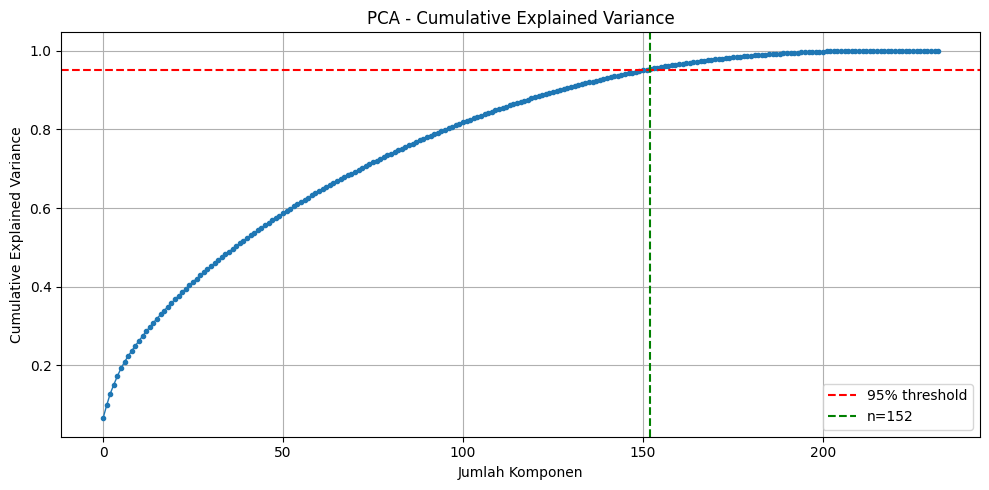

In [44]:
plt.figure(figsize=(10, 5))
plt.plot(cum_var, marker='.', linewidth=1)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% threshold')
plt.axvline(x=n_95, color='g', linestyle='--', label=f'n={n_95}')
plt.xlabel('Jumlah Komponen')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [45]:
pca = PCA(n_components=n_95)
X_pca = pca.fit_transform(X_reduced)

X_pca = pd.DataFrame(
    X_pca,
    columns=[f'PC{i+1}' for i in range(n_95)]
)

print("Shape X_reduced:", X_reduced.shape)
print("Shape X_pca:", X_pca.shape)
print("Total variance terjaga:", round(pca.explained_variance_ratio_.sum(), 4))

Shape X_reduced: (1449, 233)
Shape X_pca: (1449, 152)
Total variance terjaga: 0.9511


In [46]:
df_final = X_reduced.copy()
df_final['SalePrice'] = y.values
df_final.to_csv('5054251031_BimaSatriawan_Tugas_Praproses_Data.csv', index=False)
print("Dataset lengkap disimpan:", df_final.shape)

df_pca = X_pca.copy()
df_pca['SalePrice'] = y.values
df_pca.to_csv('5054251031_BimaSatriawan_Tugas_Praproses_Data_PCA.csv', index=False)
print("Dataset PCA disimpan:", df_pca.shape)

Dataset lengkap disimpan: (1449, 234)
Dataset PCA disimpan: (1449, 153)
